# Derivable Judgement: A Statistical Decision-Making Model
**Role:** Data analyst at a public health research organization
**Goal:** Use inferential statistics to find which factors affect disease (diabetes and hypertension).


## Part A - Theory (short notes)
The full notes with definitions are in `Theory_Notes.pdf`. Here is a quick summary.

| Concept | Simple meaning |
|---|---|
| Inferential statistics | Using a small sample to make conclusions about a big population. |
| Hypothesis testing | A method to check a claim using data. It has H0 (no effect), H1 (some effect), a test statistic, a significance level (alpha) and a decision. |
| Confidence interval | A range of values that likely contains the true population value (for example 95%). |
| Critical value | The cut-off value of the test statistic. If our statistic goes beyond it, we reject H0. |
| p-value | The chance of getting our result (or more extreme) if H0 is true. Small p-value means strong evidence against H0. |
| Type I error | Rejecting H0 when it is actually true (false alarm). Chance = alpha. |
| Type II error | Not rejecting H0 when it is actually false (missed finding). Chance = beta. |
| z-test | Compares means when sample is large (n > 30) and population standard deviation is known. |
| t-test | Compares means when sample is small or population standard deviation is unknown. |
| Chi-square test | Checks if two categorical variables are related. |
| ANOVA | Checks if the means of 3 or more groups are different. |
| Covariance | Shows if two variables move together. Its size depends on the units. |
| Correlation | Covariance scaled between -1 and +1. Shows strength and direction of a linear link. |

## Part B - Data Analysis and Testing

### Step 1: Load and look at the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
import os

os.makedirs("images", exist_ok=True)
sns.set_theme(style="whitegrid")
ALPHA = 0.05   # significance level used in all tests

df = pd.read_csv("data/health_records.csv")
print("Shape:", df.shape)
df.head()

Shape: (1000, 15)


,record_id,age_group,age,weight,gender,region,smoking_status,exercise_frequency,bmi,blood_pressure,diabetes,hypertension,cholesterol_level,glucose_level,visit_date
0,7c419289-dd3f-4e21-8787-c00ada1b551e,46-60,47,50,Female,North,Non-Smoker,Rarely,18.9,119.5,False,True,175.2,81.9,2024-12-25
1,ba92630e-ff66-4380-9814-c3ef464c805a,18-25,25,63,Male,West,Non-Smoker,Weekly,22.6,116.0,False,False,146.9,95.7,2023-08-13
2,a246b841-72e5-4e3c-85be-39fb08097df5,46-60,54,84,Male,West,Non-Smoker,Rarely,25.5,122.5,False,False,178.9,93.3,2023-02-12
3,8d3b05a6-ff0d-4076-9379-e928758ec6ed,46-60,57,81,Male,West,Smoker,Weekly,29.0,111.1,False,False,197.7,104.7,2023-05-13
4,f1d95800-d4e2-4b29-b15e-bbadd6a1f72e,18-25,18,66,Male,South,Non-Smoker,Weekly,23.0,85.0,False,False,182.8,85.5,2023-10-29


In [2]:
print(df.dtypes)
print("\nMissing values:", df.isna().sum().sum())
df.describe().round(2)

record_id                 str
age_group                 str
age                     int64
weight                  int64
gender                    str
region                    str
smoking_status            str
exercise_frequency        str
bmi                   float64
blood_pressure        float64
diabetes                 bool
hypertension             bool
cholesterol_level     float64
glucose_level         float64
visit_date                str
dtype: object

Missing values: 0


,age,weight,bmi,blood_pressure,cholesterol_level,glucose_level
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,42.02,64.53,22.85,109.05,172.48,93.56
std,14.79,11.51,3.32,10.64,27.15,18.21
min,18.00,40.00,15.00,85.00,110.00,65.00
25%,31.00,56.00,20.70,101.48,154.48,81.30
50%,42.00,64.00,22.70,109.20,173.20,89.10
75%,51.00,72.00,25.10,116.70,190.82,100.12
max,85.00,102.00,32.40,137.30,262.00,152.60


**Interpretation:** The dataset has 1000 rows and 15 columns. There are no missing values, so no cleaning is needed.

### Step 2: Quick charts (EDA)

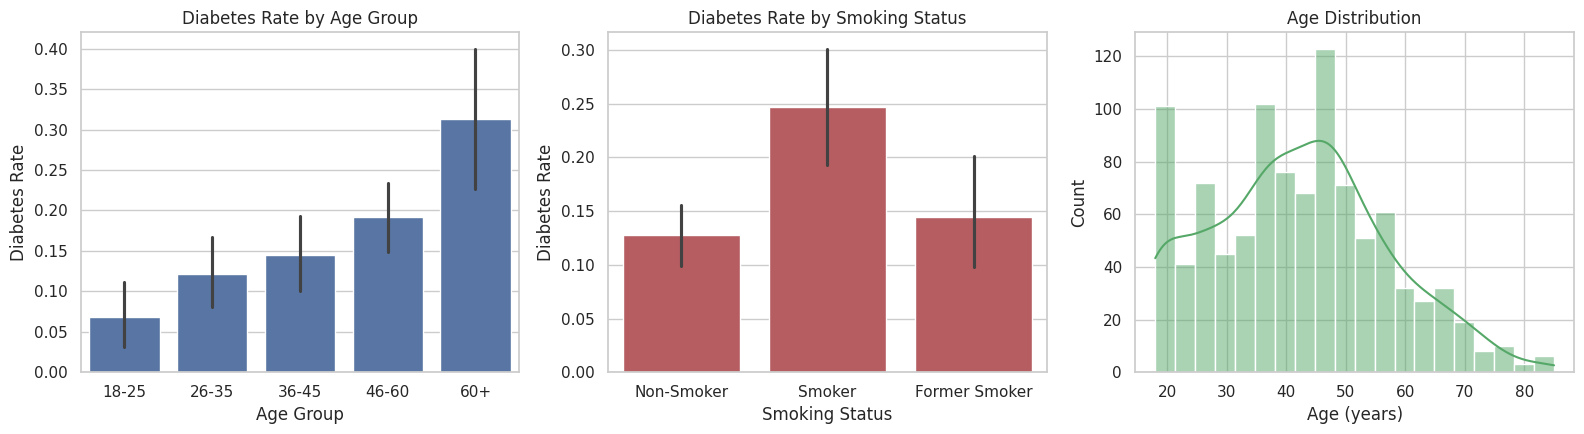

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

order = ["18-25", "26-35", "36-45", "46-60", "60+"]
sns.barplot(data=df, x="age_group", y=df["diabetes"].astype(int), order=order, ax=ax[0], color="#4C72B0")
ax[0].set_title("Diabetes Rate by Age Group"); ax[0].set_xlabel("Age Group"); ax[0].set_ylabel("Diabetes Rate")

sns.barplot(data=df, x="smoking_status", y=df["diabetes"].astype(int), ax=ax[1], color="#C44E52")
ax[1].set_title("Diabetes Rate by Smoking Status"); ax[1].set_xlabel("Smoking Status"); ax[1].set_ylabel("Diabetes Rate")

sns.histplot(df["age"], bins=20, kde=True, ax=ax[2], color="#55A868")
ax[2].set_title("Age Distribution"); ax[2].set_xlabel("Age (years)")

plt.tight_layout()
plt.savefig("images/01_eda_overview.png", dpi=150)
plt.show()

**Interpretation:** Diabetes rate goes up with age. Smokers also show a higher diabetes rate than non-smokers. Age is spread in a bell-like shape, centered near 42 years.

### Step 3: Confidence Intervals (95%)
We use the t-distribution: `mean +/- t_critical * (std / sqrt(n))`

In [4]:
def conf_int(series, conf=0.95):
    n = series.count()
    mean = series.mean()
    sem = stats.sem(series)
    t_crit = stats.t.ppf((1 + conf) / 2, df=n - 1)
    return mean, mean - t_crit * sem, mean + t_crit * sem, t_crit

rows = []
for col in ["age", "weight", "bmi", "blood_pressure", "cholesterol_level", "glucose_level"]:
    m, lo, hi, tc = conf_int(df[col])
    rows.append([col, round(m, 2), round(lo, 2), round(hi, 2), round(tc, 3)])

ci_table = pd.DataFrame(rows, columns=["Variable", "Mean", "CI Lower", "CI Upper", "Critical t"])
ci_table.to_csv("data/confidence_intervals.csv", index=False)
ci_table

,Variable,Mean,CI Lower,CI Upper,Critical t
0,age,42.02,41.11,42.94,1.962
1,weight,64.53,63.82,65.25,1.962
2,bmi,22.85,22.65,23.06,1.962
3,blood_pressure,109.05,108.39,109.71,1.962
4,cholesterol_level,172.48,170.80,174.17,1.962
5,glucose_level,93.56,92.43,94.69,1.962


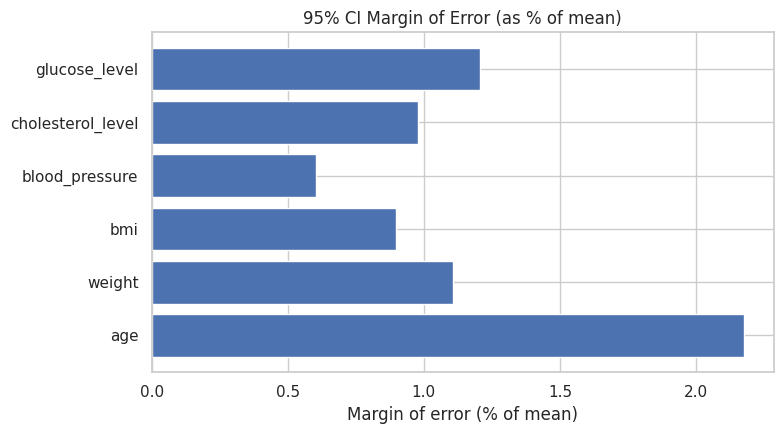

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df = ci_table.copy()
plot_df["pct_err"] = (plot_df["CI Upper"] - plot_df["CI Lower"]) / 2 / plot_df["Mean"] * 100
ax.barh(plot_df["Variable"], plot_df["pct_err"], color="#4C72B0")
ax.set_title("95% CI Margin of Error (as % of mean)")
ax.set_xlabel("Margin of error (% of mean)")
plt.tight_layout()
plt.savefig("images/02_confidence_intervals.png", dpi=150)
plt.show()

**Interpretation:** We are 95% sure that the true population mean of each variable lies inside its interval. All intervals are narrow because the sample is large (n = 1000). Narrow interval = our estimate is precise.

### Step 4: Hypothesis 1 - Smoking and Diabetes (Chi-square test)
- **H0:** Smoking status and diabetes are independent (smoking has no effect).
- **H1:** Smoking status and diabetes are related (smoking affects diabetes).
- Test: Chi-square test of independence, alpha = 0.05

In [6]:
ct = pd.crosstab(df["smoking_status"], df["diabetes"])
print(ct, "\n")

chi2, p, dof, expected = stats.chi2_contingency(ct)
crit = stats.chi2.ppf(1 - ALPHA, dof)

print(f"Chi-square statistic : {chi2:.3f}")
print(f"Degrees of freedom   : {dof}")
print(f"Critical value       : {crit:.3f}")
print(f"p-value              : {p:.6f}")
print("Decision             :", "REJECT H0" if p < ALPHA else "FAIL TO REJECT H0")

diabetes        False  True 
smoking_status              
Former Smoker     166     28
Non-Smoker        477     70
Smoker            195     64 

Chi-square statistic : 18.930
Degrees of freedom   : 2
Critical value       : 5.991
p-value              : 0.000078
Decision             : REJECT H0


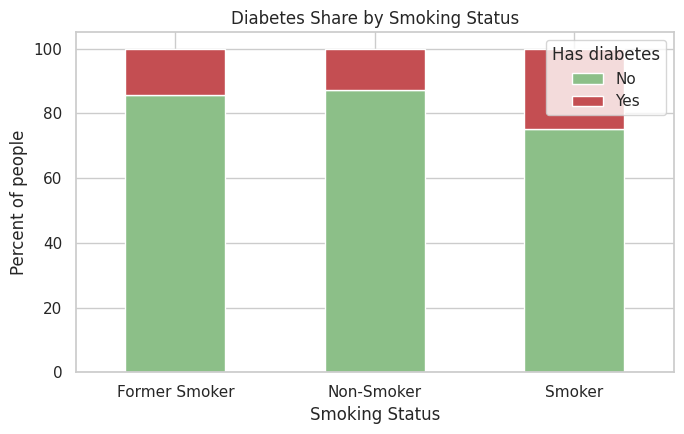

In [7]:
pct = pd.crosstab(df["smoking_status"], df["diabetes"], normalize="index") * 100
ax = pct.plot(kind="bar", stacked=True, figsize=(7, 4.5), color=["#8CBF88", "#C44E52"])
ax.set_title("Diabetes Share by Smoking Status")
ax.set_xlabel("Smoking Status"); ax.set_ylabel("Percent of people")
ax.legend(title="Has diabetes", labels=["No", "Yes"])
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("images/03_smoking_vs_diabetes.png", dpi=150)
plt.show()

**Result:** The chi-square value is bigger than the critical value and the p-value is less than 0.05, so we **reject H0**.
**Interpretation:** Smoking status and diabetes are related. Smokers have a clearly higher diabetes rate than non-smokers.

### Step 5: Hypothesis 2 - BMI of diabetic vs non-diabetic people (t-test and z-test)
- **H0:** Mean BMI of diabetic people = mean BMI of non-diabetic people.
- **H1:** Mean BMI of the two groups is different.
- Test: Welch's two-sample t-test (does not assume equal variance). Because both groups are large, we also show the z-test.

In [8]:
g1 = df.loc[df["diabetes"], "bmi"]
g2 = df.loc[~df["diabetes"], "bmi"]
print(f"Diabetic     : n={len(g1)}, mean BMI={g1.mean():.2f}")
print(f"Non-diabetic : n={len(g2)}, mean BMI={g2.mean():.2f}\n")

# t-test
t_stat, p_t = stats.ttest_ind(g1, g2, equal_var=False)
dof = len(g1) + len(g2) - 2
t_crit = stats.t.ppf(1 - ALPHA / 2, dof)
print(f"t statistic: {t_stat:.3f} | critical t (+/-): {t_crit:.3f} | p-value: {p_t:.6f}")

# z-test (large samples)
from statsmodels.stats.weightstats import ztest
z_stat, p_z = ztest(g1, g2)
z_crit = stats.norm.ppf(1 - ALPHA / 2)
print(f"z statistic: {z_stat:.3f} | critical z (+/-): {z_crit:.3f} | p-value: {p_z:.6f}")
print("\nDecision:", "REJECT H0" if p_t < ALPHA else "FAIL TO REJECT H0")

Diabetic     : n=162, mean BMI=24.27
Non-diabetic : n=838, mean BMI=22.58

t statistic: 5.897 | critical t (+/-): 1.962 | p-value: 0.000000
z statistic: 6.037 | critical z (+/-): 1.960 | p-value: 0.000000

Decision: REJECT H0


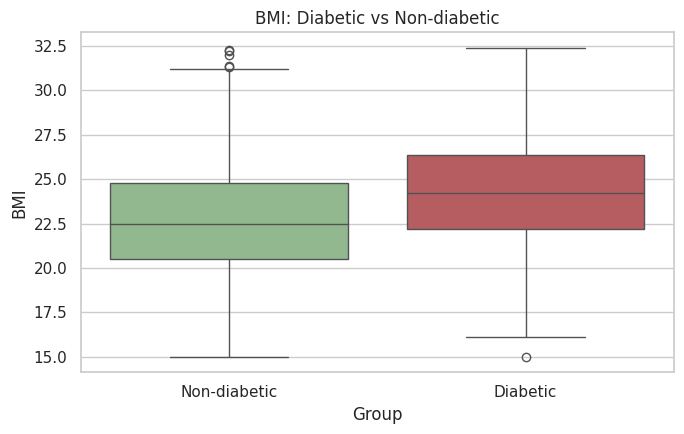

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(x=df["diabetes"].map({True: "Diabetic", False: "Non-diabetic"}), y=df["bmi"],
            hue=df["diabetes"].map({True: "Diabetic", False: "Non-diabetic"}),
            palette=["#8CBF88", "#C44E52"], legend=False, ax=ax)
ax.set_title("BMI: Diabetic vs Non-diabetic"); ax.set_xlabel("Group"); ax.set_ylabel("BMI")
plt.tight_layout()
plt.savefig("images/04_bmi_ttest.png", dpi=150)
plt.show()

**Result:** Both t-test and z-test give the same answer. The test statistic is beyond the critical value and p < 0.05, so we **reject H0**.
**Interpretation:** Diabetic people have a higher average BMI than non-diabetic people. This difference is not due to chance.

### Step 6: Hypothesis 3 - Gender and Hypertension (Chi-square test)
- **H0:** Gender and hypertension are independent.
- **H1:** Gender and hypertension are related.

In [10]:
ct2 = pd.crosstab(df["gender"], df["hypertension"])
print(ct2, "\n")
chi2_2, p_2, dof_2, exp_2 = stats.chi2_contingency(ct2)
print(f"Chi-square: {chi2_2:.3f} | dof: {dof_2} | critical: {stats.chi2.ppf(1-ALPHA, dof_2):.3f} | p-value: {p_2:.4f}")
print("Decision:", "REJECT H0" if p_2 < ALPHA else "FAIL TO REJECT H0")
print("\nCheck: smallest expected count =", exp_2.min().round(2))

hypertension  False  True 
gender                    
Female          425     38
Male            448     42
Other            40      7 

Chi-square: 2.422 | dof: 2 | critical: 5.991 | p-value: 0.2980
Decision: FAIL TO REJECT H0

Check: smallest expected count = 4.09


**Result:** The p-value (about 0.30) is more than 0.05 and the chi-square value is below the critical value, so we **fail to reject H0**.
**Interpretation:** We do not find enough evidence that gender is linked with hypertension. Note: the "Other" group is small (about 4% of people), so its expected counts are low and this result should be read with care.

### Step 7: ANOVA - Do age groups differ in disease rate?
- **H0:** Mean disease rate is the same in all 5 age groups.
- **H1:** At least one age group has a different disease rate.
- Test: One-way ANOVA (disease is coded 0/1, so the group mean = disease rate).

In [11]:
order = ["18-25", "26-35", "36-45", "46-60", "60+"]
df["diabetes_int"] = df["diabetes"].astype(int)
df["hypertension_int"] = df["hypertension"].astype(int)

for disease in ["diabetes_int", "hypertension_int"]:
    groups = [df.loc[df["age_group"] == g, disease] for g in order]
    f_stat, p_f = stats.f_oneway(*groups)
    k, n = len(groups), len(df)
    f_crit = stats.f.ppf(1 - ALPHA, k - 1, n - k)
    print(f"{disease.replace('_int','').title():13s} F = {f_stat:7.3f} | critical F = {f_crit:.3f} | p = {p_f:.2e} -> "
          f"{'REJECT H0' if p_f < ALPHA else 'FAIL TO REJECT H0'}")

Diabetes      F =   8.831 | critical F = 2.381 | p = 5.24e-07 -> REJECT H0
Hypertension  F =  18.274 | critical F = 2.381 | p = 1.69e-14 -> REJECT H0


In [12]:
model = ols("diabetes_int ~ C(age_group)", data=df).fit()
print(sm.stats.anova_lm(model, typ=2).round(4))

                sum_sq     df       F  PR(>F)
C(age_group)    4.6544    4.0  8.8311     0.0
Residual      131.1016  995.0     NaN     NaN


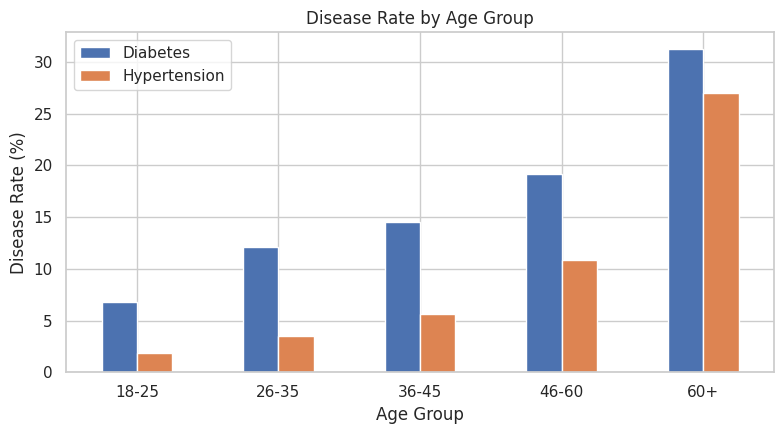

In [13]:
rates = df.groupby("age_group")[["diabetes_int", "hypertension_int"]].mean().reindex(order) * 100
ax = rates.plot(kind="bar", figsize=(8, 4.5), color=["#4C72B0", "#DD8452"])
ax.set_title("Disease Rate by Age Group")
ax.set_xlabel("Age Group"); ax.set_ylabel("Disease Rate (%)")
ax.legend(["Diabetes", "Hypertension"]); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("images/05_anova_age_groups.png", dpi=150)
plt.show()

**Result:** For both diseases, F is bigger than the critical F and p < 0.05, so we **reject H0**.
**Interpretation:** Disease rate is not the same in all age groups. It rises clearly with age, and the 60+ group has the highest rate.

### Step 8: Covariance and Correlation

In [14]:
cont = ["age", "weight", "bmi", "blood_pressure", "cholesterol_level", "glucose_level"]
cov = df[cont].cov().round(2)
corr = df[cont].corr().round(3)
cov.to_csv("data/covariance_matrix.csv")
corr.to_csv("data/correlation_matrix.csv")
print("Covariance (Age vs BMI):", round(df["age"].cov(df["bmi"]), 3))
r, p_r = stats.pearsonr(df["age"], df["bmi"])
print(f"Correlation (Age vs BMI): r = {r:.3f}, p-value = {p_r:.2e}")
corr

Covariance (Age vs BMI): 14.22
Correlation (Age vs BMI): r = 0.290, p-value = 8.41e-21


,age,weight,bmi,blood_pressure,cholesterol_level,glucose_level
age,1.000,0.228,0.290,0.518,0.300,0.338
weight,0.228,1.000,0.771,0.346,0.167,0.262
bmi,0.290,0.771,1.000,0.396,0.228,0.355
blood_pressure,0.518,0.346,0.396,1.000,0.163,0.245
cholesterol_level,0.300,0.167,0.228,0.163,1.000,0.094
glucose_level,0.338,0.262,0.355,0.245,0.094,1.000


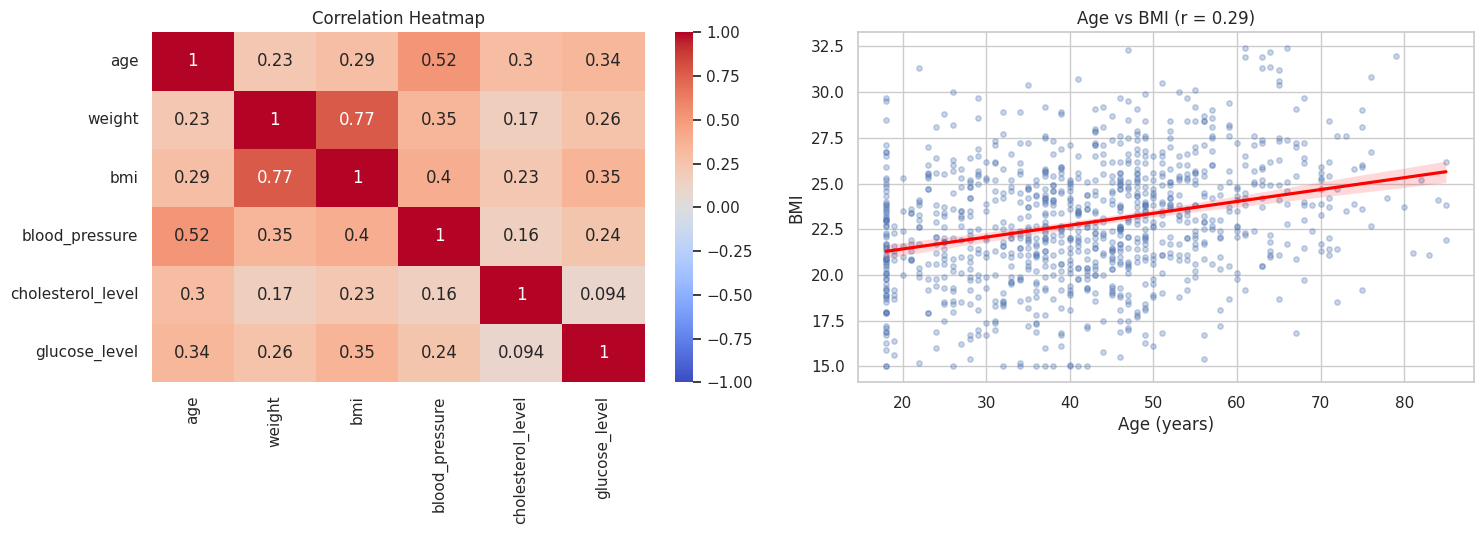

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Correlation Heatmap")
sns.regplot(data=df, x="age", y="bmi", scatter_kws={"alpha": 0.3, "s": 15}, line_kws={"color": "red"}, ax=ax[1])
ax[1].set_title(f"Age vs BMI (r = {r:.2f})"); ax[1].set_xlabel("Age (years)"); ax[1].set_ylabel("BMI")
plt.tight_layout()
plt.savefig("images/06_correlation.png", dpi=150)
plt.show()

**Interpretation:** Age and BMI have a **positive** covariance and a weak-to-moderate positive correlation. Older people tend to have a slightly higher BMI. Blood pressure and cholesterol also rise with age and BMI. Weight and BMI are strongly related, as expected. Remember: correlation does not prove cause.

### Step 9: Summary of all results

In [16]:
summary = pd.DataFrame([
    ["Smoking vs Diabetes", "Chi-square", round(chi2, 3), f"{p:.2e}", "Reject H0", "Smoking is linked with diabetes"],
    ["BMI: Diabetic vs Non-diabetic", "Welch t-test / z-test", round(t_stat, 3), f"{p_t:.2e}", "Reject H0", "Diabetic people have higher BMI"],
    ["Gender vs Hypertension", "Chi-square", round(chi2_2, 3), f"{p_2:.4f}",
     "Reject H0" if p_2 < ALPHA else "Fail to reject H0",
     "Gender linked with hypertension" if p_2 < ALPHA else "No clear link with gender"],
    ["Age groups vs Diabetes", "ANOVA", round(stats.f_oneway(*[df.loc[df.age_group==g,'diabetes_int'] for g in order])[0], 3),
     f"{stats.f_oneway(*[df.loc[df.age_group==g,'diabetes_int'] for g in order])[1]:.2e}", "Reject H0", "Diabetes rate changes with age"],
    ["Age vs BMI", "Pearson correlation", round(r, 3), f"{p_r:.2e}", "Reject H0 (r = 0)", "Weak positive link"],
], columns=["Question", "Test", "Statistic", "p-value", "Decision", "Meaning"])
summary.to_csv("data/results_summary.csv", index=False)
summary

,Question,Test,Statistic,p-value,Decision,Meaning
0,Smoking vs Diabetes,Chi-square,18.930,7.75e-05,Reject H0,Smoking is linked with diabetes
1,BMI: Diabetic vs Non-diabetic,Welch t-test / z-test,5.897,1.36e-08,Reject H0,Diabetic people have higher BMI
2,Gender vs Hypertension,Chi-square,2.422,0.2980,Fail to reject H0,No clear link with gender
3,Age groups vs Diabetes,ANOVA,8.831,5.24e-07,Reject H0,Diabetes rate changes with age
4,Age vs BMI,Pearson correlation,0.290,8.41e-21,Reject H0 (r = 0),Weak positive link


## Final Judgement
1. **Age** is the strongest factor. Both diabetes and hypertension rise with age.
2. **Smoking** is linked with higher diabetes rate.
3. **BMI** is higher in diabetic people.
4. **Gender** shows no clear link with hypertension in this data.

**Limits:** The data is synthetic. Tests show *link*, not *cause*. A small sample group ("Other" gender) can give weak results.